In [2]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

import time
set_config(display="text")  # displays text representation of estimators

In [3]:
dataset = pd.read_csv("../../data/data_final.csv")

diagnosis_variables = []

with open("../../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [4]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False))

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [5]:
# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

In [5]:
# Step 1: Split data - first fold is the TEST SET (held out for final evaluation)
from sksurv.ensemble import GradientBoostingSurvivalAnalysis

sgkf_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)

# Get first fold as test set
first_split = list(sgkf_outer.split(X=data_x, y=survival_dataset['Regional LN recurrence']))[0]
train_pool_index, test_index = first_split

# Test set - held out for final evaluation
x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
test_dataset = survival_dataset.iloc[test_index].copy()

# Training pool - will be used for 4-fold CV recalibration evaluation
x_train_pool = data_x.iloc[train_pool_index]
y_train_pool = data_y[train_pool_index]
train_pool_dataset = survival_dataset.iloc[train_pool_index].copy()

print("="*70)
print("DATA SPLIT")
print("="*70)
print(f"Test set (held out): {len(x_test)} samples, {y_test['event'].sum()} events")
print(f"Training pool (for 4-fold CV): {len(x_train_pool)} samples, {y_train_pool['event'].sum()} events")

DATA SPLIT
Test set (held out): 594 samples, 6 events
Training pool (for 4-fold CV): 2376 samples, 27 events


In [6]:
# Load best hyperparameters from repeated CV results
best_results = pd.read_csv("../../results/repeated_sub/gbm_sub.csv")
best_params = best_results.iloc[0]  # Row 0 as identified in results.ipynb

print("\nBest hyperparameters (Row 0 from repeated CV):")
print(f"  learning_rate: {best_params['learning_rate']}")
print(f"  n_estimators: {int(best_params['n_estimators'])}")
print(f"  max_depth: {int(best_params['max_depth'])}")
print(f"  min_samples_split: {int(best_params['min_samples_split'])}")
print(f"  n_controls_per_case: {int(best_params['n_controls_per_case'])}")
print(f"  c-index-ipcw_mean (CV): {best_params['c-index-ipcw_mean']:.4f}")

# Step 2: 4-fold CV on the training pool for recalibration evaluation
sgkf_inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Storage for all out-of-fold predictions
all_val_y = []  # True outcomes
all_val_preds_before = []  # Survival predictions BEFORE recalibration
all_val_preds_after = []  # Survival predictions AFTER recalibration
all_val_risk_before = []  # Risk scores BEFORE recalibration
all_val_risk_after = []  # Risk scores AFTER recalibration
all_fold_feature_importances = []  # Feature importances from each fold

# Time points for evaluation
time_points_eval = [650, 1100, 1600, 1825]

# Time points for IBS (5th-95th percentile) - will be calculated from training pool
event_times_pool = y_train_pool['time'][y_train_pool['event'] == 1]
times_ibs = np.percentile(event_times_pool, np.linspace(5, 95, 20))
times_ibs = np.unique(np.sort(times_ibs))

print("\n" + "="*70)
print("4-FOLD CV RECALIBRATION EVALUATION (on training pool)")
print("="*70)

for fold_idx, (train_index, val_index) in enumerate(sgkf_inner.split(X=x_train_pool, y=train_pool_dataset['Regional LN recurrence'])):
    print(f"\n--- Fold {fold_idx + 1}/4 ---")
    
    # Get train and validation data FROM THE TRAINING POOL
    x_train_fold = x_train_pool.iloc[train_index]
    y_train_fold = y_train_pool[train_index]
    x_val = x_train_pool.iloc[val_index]
    y_val = y_train_pool[val_index]
    train_fold_df = train_pool_dataset.iloc[train_index].copy()
    
    print(f"  Training samples (this fold): {len(x_train_fold)}")
    print(f"  Validation samples: {len(x_val)}")
    print(f"  Training events: {y_train_fold['event'].sum()}")
    print(f"  Validation events: {y_val['event'].sum()}")
    
    # Apply case-control subsampling to this fold's training data
    x_train_sub, y_train_sub, sub_dataset = sample_case_control(
        train_fold=train_fold_df,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_controls_per_case=int(best_params['n_controls_per_case']),
        feature_columns=feature_columns,
        random_state=12
    )
    print(f"  Subsampled training samples: {len(x_train_sub)}")
    
    # Train model on subsampled data (GBM doesn't need scaling)
    model = GradientBoostingSurvivalAnalysis(
        learning_rate=best_params['learning_rate'],
        n_estimators=int(best_params['n_estimators']),
        max_depth=int(best_params['max_depth']),
        min_samples_split=int(best_params['min_samples_split']),
        random_state=12
    )
    model.fit(x_train_sub, y_train_sub)
    
    # ============================================
    # BEFORE RECALIBRATION: Get validation predictions
    # ============================================
    surv_funcs_before = model.predict_survival_function(x_val)
    preds_before = np.array([[fn(t) for t in time_points_eval] for fn in surv_funcs_before])
    risk_before = model.predict(x_val)
    
    # ============================================
    # BRESLOW RECALIBRATION: Use NON-subsampled training fold data
    # ============================================
    # Get risk scores on non-subsampled training fold data
    train_risk_scores = model.predict(x_train_fold)
    risk_scores_train = np.exp(train_risk_scores)
    
    # Breslow baseline hazard estimation using this fold's training data
    survival_times = y_train_fold['time']
    events = y_train_fold['event']
    unique_times = np.sort(np.unique(survival_times[events == 1]))
    baseline_hazard = []
    
    for t in unique_times:
        d_t = np.sum((survival_times == t) & (events == 1))
        at_risk = survival_times >= t
        risk_sum = np.sum(risk_scores_train[at_risk])
        h_0_t = d_t / risk_sum if risk_sum > 0 else 0
        baseline_hazard.append(h_0_t)
    
    baseline_hazard_df = pd.DataFrame({
        'timeline': unique_times,
        'baseline_hazard': baseline_hazard
    })
    baseline_hazard_df['baseline_cumulative_hazard'] = np.cumsum(baseline_hazard_df['baseline_hazard'])
    
    # ============================================
    # AFTER RECALIBRATION: Get validation predictions
    # ============================================
    val_risk_scores = model.predict(x_val)
    risk_ratios_val = np.exp(val_risk_scores)
    
    # Calculate survival predictions at each time point using recalibrated baseline
    preds_after = np.zeros((len(x_val), len(time_points_eval)))
    for i, t in enumerate(time_points_eval):
        if t <= baseline_hazard_df['timeline'].min():
            cum_baseline_hazard = 0
        elif t >= baseline_hazard_df['timeline'].max():
            cum_baseline_hazard = baseline_hazard_df['baseline_cumulative_hazard'].iloc[-1]
        else:
            cum_baseline_hazard = np.interp(t, 
                                           baseline_hazard_df['timeline'], 
                                           baseline_hazard_df['baseline_cumulative_hazard'])
        preds_after[:, i] = np.exp(-cum_baseline_hazard * risk_ratios_val)
    
    # Store predictions
    all_val_y.append(y_val)
    all_val_preds_before.append(preds_before)
    all_val_preds_after.append(preds_after)
    all_val_risk_before.append(risk_before)
    all_val_risk_after.append(val_risk_scores)
    # Store feature importances from this fold
    all_fold_feature_importances.append(model.feature_importances_.copy())
    
    print(f"  ✓ Fold {fold_idx + 1} completed")


print("\n" + "="*70)
print("All 4 folds completed!")


Best hyperparameters (Row 0 from repeated CV):
  learning_rate: 0.1
  n_estimators: 500
  max_depth: 2
  min_samples_split: 10
  n_controls_per_case: 15
  c-index-ipcw_mean (CV): 0.7785

4-FOLD CV RECALIBRATION EVALUATION (on training pool)

--- Fold 1/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 21
  Validation events: 6
  Subsampled training samples: 325
  ✓ Fold 1 completed

--- Fold 2/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 307
  ✓ Fold 2 completed

--- Fold 3/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 320
  ✓ Fold 3 completed

--- Fold 4/4 ---
  Training samples (this fold): 1782
  Validation samples: 594
  Training events: 20
  Validation events: 7
  Subsampled training samples: 306
  ✓ Fold 4 completed

All 4 folds completed!


In [7]:
# Combine all out-of-fold predictions and calculate metrics
print("="*70)
print("COMBINED OUT-OF-FOLD RESULTS")
print("="*70)

# Concatenate all validation data
combined_y = np.concatenate([y for y in all_val_y])
combined_preds_before = np.vstack(all_val_preds_before)
combined_preds_after = np.vstack(all_val_preds_after)
combined_risk_before = np.concatenate(all_val_risk_before)
combined_risk_after = np.concatenate(all_val_risk_after)

print(f"\nTotal samples (combined): {len(combined_y)}")
print(f"Total events: {combined_y['event'].sum()}")
print(f"Prediction shape: {combined_preds_before.shape}")

# Calculate time points for IBS (5th to 95th percentile of survival times)
min_time = np.percentile(combined_y['time'], 5)
max_time = np.percentile(combined_y['time'], 95)
times_ibs = np.array([t for t in time_points_eval if min_time <= t <= max_time])
print(f"\nTime range for IBS: {min_time:.0f} - {max_time:.0f} days (5th-95th percentile)")
print(f"Time points for IBS: {times_ibs}")
valid_time_idx = [i for i, t in enumerate(time_points_eval) if min_time <= t <= max_time]
# Filter predictions to only include valid time points
valid_time_idx = [i for i, t in enumerate(time_points_eval) if t <= max_time]
preds_before_filtered = combined_preds_before[:, valid_time_idx]
preds_after_filtered = combined_preds_after[:, valid_time_idx]

# Calculate Integrated Brier Score
try:
    ibs_before = integrated_brier_score(combined_y, combined_y, preds_before_filtered, times_ibs)
    ibs_after = integrated_brier_score(combined_y, combined_y, preds_after_filtered, times_ibs)
    
    print(f"\n" + "="*70)
    print("INTEGRATED BRIER SCORE (Combined Out-of-Fold)")
    print("="*70)
    print(f"  Before recalibration: {ibs_before:.4f}")
    print(f"  After recalibration:  {ibs_after:.4f}")
    print(f"  Improvement:          {ibs_before - ibs_after:.4f} ({(ibs_before - ibs_after)/ibs_before*100:.1f}%)")
    print("="*70)
except Exception as e:
    print(f"Error calculating IBS: {e}")
    ibs_before, ibs_after = None, None

# ============================================
# Save predictions to CSV
# ============================================
# Create DataFrame with all predictions
predictions_df = pd.DataFrame({
    'event': combined_y['event'],
    'time': combined_y['time'],
    'risk_before': combined_risk_before,
    'risk_after': combined_risk_after,
})

# Add survival predictions at each fixed time point (for calibration)
for i, t in enumerate(time_points_eval):
    predictions_df[f'surv_before_{t}d'] = combined_preds_before[:, i]
    predictions_df[f'surv_after_{t}d'] = combined_preds_after[:, i]

# Save to CSV
predictions_df.to_csv('gbm_predictions.csv', index=False)

print(f"\n✓ Predictions saved to '../../results/predictions/gbm_breslow_predictions.csv'")

COMBINED OUT-OF-FOLD RESULTS

Total samples (combined): 2376
Total events: 27
Prediction shape: (2376, 4)

Time range for IBS: 357 - 2737 days (5th-95th percentile)
Time points for IBS: [ 650 1100 1600 1825]

INTEGRATED BRIER SCORE (Combined Out-of-Fold)
  Before recalibration: 0.0136
  After recalibration:  0.0087
  Improvement:          0.0049 (36.3%)

✓ Predictions saved to '../../results/predictions/gbm_breslow_predictions.csv'


In [8]:
# ============================================
# STATISTICAL TESTS FOR IBS COMPARISON (REPEATED CV)
# ============================================
from scipy.stats import wilcoxon
from scipy.stats import levene  # Brown-Forsythe test

print("="*70)
print("STATISTICAL TESTS: IBS BEFORE vs AFTER RECALIBRATION")
print("REPEATED CROSS-VALIDATION (5 repetitions × 4 folds = 20 experiments)")
print("="*70)

# Perform repeated cross-validation to get 20 experiments
n_repetitions = 5
n_folds = 4
total_experiments = n_repetitions * n_folds

# Storage for all experiments
all_experiments_ibs_before = []
all_experiments_ibs_after = []
experiment_details = []

# Time points for IBS (5th-95th percentile) - will be calculated from training pool
event_times_pool = y_train_pool['time'][y_train_pool['event'] == 1]
times_ibs = np.percentile(event_times_pool, np.linspace(5, 95, 20))
times_ibs = np.unique(np.sort(times_ibs))

print("Running repeated cross-validation for robust statistical testing:")
print(f"  Repetitions: {n_repetitions}")
print(f"  Folds per repetition: {n_folds}")
print(f"  Total experiments: {total_experiments}")

for rep in range(n_repetitions):
    print(f"\n--- Repetition {rep + 1}/{n_repetitions} ---")
    
    # Create new CV split with different random state for each repetition
    sgkf_rep = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=12 + rep)
    
    for fold_idx, (train_index, val_index) in enumerate(sgkf_rep.split(X=x_train_pool, y=train_pool_dataset['Regional LN recurrence'])):
        experiment_num = rep * n_folds + fold_idx + 1
        
        # Get train and validation data
        x_train_fold = x_train_pool.iloc[train_index]
        y_train_fold = y_train_pool[train_index]
        x_val = x_train_pool.iloc[val_index]
        y_val = y_train_pool[val_index]
        train_fold_df = train_pool_dataset.iloc[train_index].copy()
        
        # Apply case-control subsampling
        x_train_sub, y_train_sub, sub_dataset = sample_case_control(
            train_fold=train_fold_df,
            event_col='Regional LN recurrence',
            time_col='Survival days',
            n_controls_per_case=int(best_params['n_controls_per_case']),
            feature_columns=feature_columns,
            random_state=12 + rep  # Different random state for each repetition
        )
        
        # Train model (GBM doesn't need scaling)
        model = GradientBoostingSurvivalAnalysis(
            learning_rate=best_params['learning_rate'],
            n_estimators=int(best_params['n_estimators']),
            max_depth=int(best_params['max_depth']),
            min_samples_split=int(best_params['min_samples_split']),
            random_state=12 + rep  # Different random state for each repetition
        )
        model.fit(x_train_sub, y_train_sub)
        
        # BEFORE RECALIBRATION: Get validation predictions
        surv_funcs_before = model.predict_survival_function(x_val)
        preds_before_ibs = np.array([[fn(t) for t in times_ibs] for fn in surv_funcs_before])
        
        # BRESLOW RECALIBRATION
        train_risk_scores = model.predict(x_train_fold)
        risk_scores_train = np.exp(train_risk_scores)
        
        # Breslow baseline hazard estimation
        survival_times = y_train_fold['time']
        events = y_train_fold['event']
        unique_times = np.sort(np.unique(survival_times[events == 1]))
        baseline_hazard = []
        
        for t in unique_times:
            d_t = np.sum((survival_times == t) & (events == 1))
            at_risk = survival_times >= t
            risk_sum = np.sum(risk_scores_train[at_risk])
            h_0_t = d_t / risk_sum if risk_sum > 0 else 0
            baseline_hazard.append(h_0_t)
        
        baseline_hazard_df = pd.DataFrame({
            'timeline': unique_times,
            'baseline_hazard': baseline_hazard
        })
        baseline_hazard_df['baseline_cumulative_hazard'] = np.cumsum(baseline_hazard_df['baseline_hazard'])
        
        # AFTER RECALIBRATION: Get validation predictions
        val_risk_scores = model.predict(x_val)
        risk_ratios_val = np.exp(val_risk_scores)
        
        # Calculate survival at IBS time points
        preds_after_ibs = np.zeros((len(risk_ratios_val), len(times_ibs)))
        for i, t in enumerate(times_ibs):
            if t <= baseline_hazard_df['timeline'].min():
                cum_baseline_hazard = 0
            elif t >= baseline_hazard_df['timeline'].max():
                cum_baseline_hazard = baseline_hazard_df['baseline_cumulative_hazard'].iloc[-1]
            else:
                cum_baseline_hazard = np.interp(t, 
                                               baseline_hazard_df['timeline'], 
                                               baseline_hazard_df['baseline_cumulative_hazard'])
            preds_after_ibs[:, i] = np.exp(-cum_baseline_hazard * risk_ratios_val)
        
        # Calculate IBS for this experiment
        try:
            ibs_before = integrated_brier_score(y_val, y_val, preds_before_ibs, times_ibs)
            ibs_after = integrated_brier_score(y_val, y_val, preds_after_ibs, times_ibs)
            
            all_experiments_ibs_before.append(ibs_before)
            all_experiments_ibs_after.append(ibs_after)
            
            improvement = ibs_before - ibs_after
            improvement_pct = (improvement / ibs_before) * 100
            
            experiment_details.append({
                'repetition': rep + 1,
                'fold': fold_idx + 1,
                'experiment': experiment_num,
                'n_train': len(x_train_fold),
                'n_val': len(x_val),
                'events_train': y_train_fold['event'].sum(),
                'events_val': y_val['event'].sum(),
                'ibs_before': ibs_before,
                'ibs_after': ibs_after,
                'improvement': improvement,
                'improvement_pct': improvement_pct
            })
            
            print(f"  Rep {rep+1}, Fold {fold_idx+1} (Exp {experiment_num:2d}): "
                  f"Before={ibs_before:.4f}, After={ibs_after:.4f}, "
                  f"Δ={improvement:.4f} ({improvement_pct:+.1f}%)")
            
        except Exception as e:
            print(f"  Rep {rep+1}, Fold {fold_idx+1} (Exp {experiment_num:2d}): Error - {e}")

# Convert to numpy arrays
all_experiments_ibs_before = np.array(all_experiments_ibs_before)
all_experiments_ibs_after = np.array(all_experiments_ibs_after)

if len(all_experiments_ibs_before) >= 8:  # Need sufficient experiments for meaningful test
    print(f"\n" + "="*70)
    print("EXPERIMENT SUMMARY")
    print("="*70)
    print(f"  Total experiments completed: {len(all_experiments_ibs_before)}")
    print(f"  Before recalibration: {all_experiments_ibs_before.mean():.4f} ± {all_experiments_ibs_before.std():.4f}")
    print(f"  After recalibration:  {all_experiments_ibs_after.mean():.4f} ± {all_experiments_ibs_after.std():.4f}")
    
    # Calculate differences
    differences = all_experiments_ibs_before - all_experiments_ibs_after
    positive_improvements = np.sum(differences > 0)
    
    print(f"  Mean improvement:     {differences.mean():.4f} ± {differences.std():.4f}")
    print(f"  Relative improvement: {(differences.mean() / all_experiments_ibs_before.mean()) * 100:.1f}%")
    print(f"  Experiments with improvement: {positive_improvements}/{len(differences)} ({positive_improvements/len(differences)*100:.1f}%)")
    
    # Perform Wilcoxon signed rank test
    try:
        if np.all(differences == 0):
            print(f"\n⚠️  All differences are zero - no improvement detected")
            statistic, p_value = np.nan, 1.0
        else:
            statistic, p_value = wilcoxon(all_experiments_ibs_before, all_experiments_ibs_after, alternative='greater')
        
        print(f"\n" + "="*60)
        print("WILCOXON SIGNED RANK TEST RESULTS")
        print("="*60)
        print(f"  Sample size: {len(all_experiments_ibs_before)} paired experiments")
        print(f"  H0: IBS_before <= IBS_after (no improvement)")
        print(f"  H1: IBS_before > IBS_after (improvement from recalibration)")
        print(f"  Test statistic: {statistic}")
        print(f"  P-value: {p_value:.6f}")
        
        # Interpret results with multiple significance levels
        significance_levels = [0.001, 0.01, 0.05]
        for alpha in significance_levels:
            if p_value < alpha:
                print(f"  Result: SIGNIFICANT at α = {alpha} (p < {alpha})")
                break
        else:
            print(f"  Result: NOT significant at conventional levels (p >= 0.05)")
        
        if p_value < 0.05:
            print(f"  Conclusion: Breslow recalibration significantly improves IBS")
        else:
            print(f"  Conclusion: No significant evidence that recalibration improves IBS")
        
        # Effect size measures
        if not np.all(differences == 0):
            print(f"\n  Effect size measures:")
            print(f"    Median improvement: {np.median(differences):.4f}")
            print(f"    25th-75th percentile: [{np.percentile(differences, 25):.4f}, {np.percentile(differences, 75):.4f}]")
            print(f"    Cohen's d: {differences.mean() / differences.std():.3f}")
            
        print("="*60)
        
    except Exception as e:
        print(f"Error performing Wilcoxon test: {e}")
    
    # Perform Brown-Forsythe test (Levene's test with median centering)
    try:
        bf_statistic, bf_p_value = levene(all_experiments_ibs_before, all_experiments_ibs_after, center='median')
        
        print(f"\n" + "="*60)
        print("BROWN-FORSYTHE TEST RESULTS")
        print("="*60)
        print(f"  Sample size: {len(all_experiments_ibs_before)} experiments per group")
        print(f"  H0: Variances are equal (σ²_before = σ²_after)")
        print(f"  H1: Variances are not equal (σ²_before ≠ σ²_after)")
        print(f"  Test statistic: {bf_statistic:.4f}")
        print(f"  P-value: {bf_p_value:.6f}")
        
        # Variance comparison
        var_before = all_experiments_ibs_before.var(ddof=1)
        var_after = all_experiments_ibs_after.var(ddof=1)
        var_ratio = var_before / var_after
        
        print(f"\n  Variance comparison:")
        print(f"    Before recalibration: {var_before:.6f}")
        print(f"    After recalibration:  {var_after:.6f}")
        print(f"    Variance ratio (before/after): {var_ratio:.4f}")
        
        # Interpret results
        if bf_p_value < 0.05:
            print(f"  Result: SIGNIFICANT difference in variances (p < 0.05)")
            if var_before > var_after:
                print(f"  Conclusion: Recalibration REDUCES variance (more consistent predictions)")
            else:
                print(f"  Conclusion: Recalibration INCREASES variance (less consistent predictions)")
        else:
            print(f"  Result: NO significant difference in variances (p >= 0.05)")
            print(f"  Conclusion: Recalibration does not significantly change prediction consistency")
        
        print("="*60)
        
    except Exception as e:
        print(f"Error performing Brown-Forsythe test: {e}")

else:
    print(f"\n⚠️  Insufficient data for statistical tests (need >= 8 experiments, got {len(all_experiments_ibs_before)})")

# Create detailed summary table
summary_df = pd.DataFrame(experiment_details)

print(f"\n" + "="*70)
print("DETAILED EXPERIMENT RESULTS")
print("="*70)
print(summary_df.to_string(index=False, float_format='%.4f'))

# Summary by repetition
if len(experiment_details) > 0:
    summary_by_rep = summary_df.groupby('repetition').agg({
        'ibs_before': ['mean', 'std'],
        'ibs_after': ['mean', 'std'],
        'improvement': ['mean', 'std'],
        'improvement_pct': ['mean', 'std']
    }).round(4)
    
    print(f"\n" + "="*70)
    print("SUMMARY BY REPETITION")
    print("="*70)
    print(summary_by_rep)

# Save results
summary_df.to_csv('gbm_breslow_ibs_repeated_cv_comparison.csv', index=False)
print(f"\n✓ Detailed results saved to 'gbm_breslow_ibs_repeated_cv_comparison.csv'")

STATISTICAL TESTS: IBS BEFORE vs AFTER RECALIBRATION
REPEATED CROSS-VALIDATION (5 repetitions × 4 folds = 20 experiments)
Running repeated cross-validation for robust statistical testing:
  Repetitions: 5
  Folds per repetition: 4
  Total experiments: 20

--- Repetition 1/5 ---
  Rep 1, Fold 1 (Exp  1): Before=0.0195, After=0.0098, Δ=0.0097 (+49.8%)
  Rep 1, Fold 2 (Exp  2): Before=0.0179, After=0.0118, Δ=0.0061 (+34.1%)
  Rep 1, Fold 3 (Exp  3): Before=0.0140, After=0.0100, Δ=0.0040 (+28.6%)
  Rep 1, Fold 4 (Exp  4): Before=0.0211, After=0.0135, Δ=0.0076 (+36.2%)

--- Repetition 2/5 ---
  Rep 2, Fold 1 (Exp  5): Before=0.0232, After=0.0120, Δ=0.0112 (+48.4%)
  Rep 2, Fold 2 (Exp  6): Before=0.0143, After=0.0090, Δ=0.0053 (+37.0%)
  Rep 2, Fold 3 (Exp  7): Before=0.0164, After=0.0125, Δ=0.0039 (+23.6%)
  Rep 2, Fold 4 (Exp  8): Before=0.0355, After=0.0119, Δ=0.0235 (+66.3%)

--- Repetition 3/5 ---
  Rep 3, Fold 1 (Exp  9): Before=0.0203, After=0.0119, Δ=0.0084 (+41.5%)
  Rep 3, Fold 2 

BRIER SCORE AT SPECIFIC TIME POINTS
 Time Point (Days)  Brier Score (Before)  Brier Score (After)  Improvement  Improvement (%)
               650                0.0037               0.0031       0.0006          15.5510
              1100                0.0089               0.0066       0.0023          25.9824
              1600                0.0209               0.0125       0.0084          40.2539
              1825                0.0297               0.0162       0.0135          45.5116


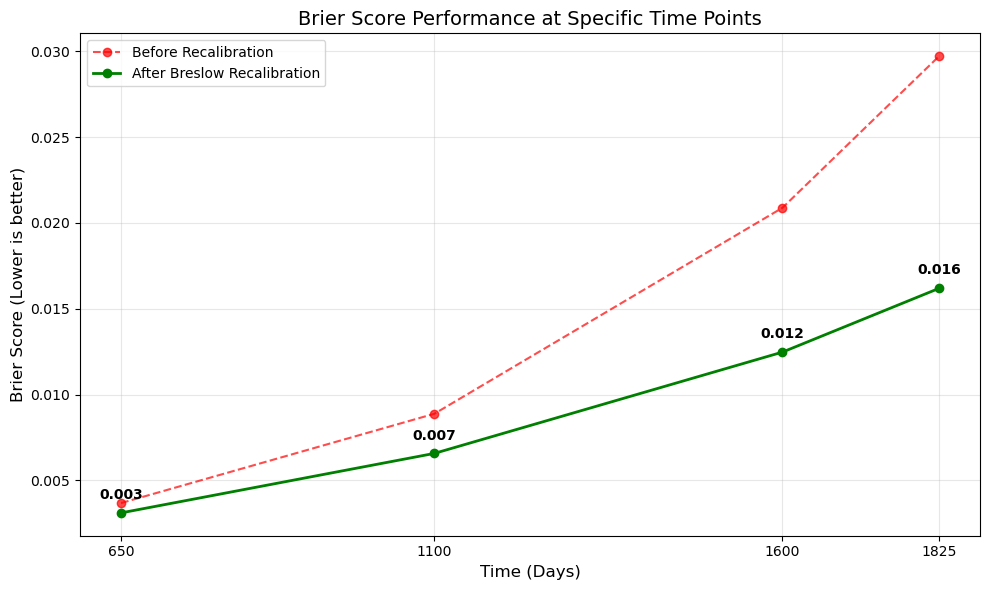

In [9]:
from sksurv.metrics import brier_score

# Time points of interest (must match time_points_eval used in previous cells)
target_times = [650, 1100, 1600, 1825]

print("="*70)
print("BRIER SCORE AT SPECIFIC TIME POINTS")
print("="*70)

try:
    # Calculate Brier score before recalibration
    # We use combined_y for both train and test to estimate censoring (IPCW) 
    # consistent with the notebook's previous IBS calculation
    _, bs_before = brier_score(
        combined_y, 
        combined_y, 
        combined_preds_before, 
        target_times
    )

    # Calculate Brier score after recalibration
    _, bs_after = brier_score(
        combined_y, 
        combined_y, 
        combined_preds_after, 
        target_times
    )

    # Create a summary DataFrame
    bs_df = pd.DataFrame({
        'Time Point (Days)': target_times,
        'Brier Score (Before)': bs_before,
        'Brier Score (After)': bs_after,
        'Improvement': bs_before - bs_after,
        'Improvement (%)': (bs_before - bs_after) / bs_before * 100
    })

    # Display table
    print(bs_df.to_string(index=False, float_format='%.4f'))

    # Optional: Visualization
    plt.figure(figsize=(10, 6))
    plt.plot(target_times, bs_before, 'o--', color='red', label='Before Recalibration', alpha=0.7)
    plt.plot(target_times, bs_after, 'o-', color='green', label='After Breslow Recalibration', linewidth=2)
    
    # Add annotations
    for i, txt in enumerate(bs_after):
        plt.annotate(f"{txt:.3f}", (target_times[i], bs_after[i]), 
                     textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

    plt.xlabel('Time (Days)', fontsize=12)
    plt.ylabel('Brier Score (Lower is better)', fontsize=12)
    plt.title('Brier Score Performance at Specific Time Points', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(target_times)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error calculating Brier scores: {e}")

GAP ANALYSIS FOR RISK SCORE DISTRIBUTION

Basic Statistics:
  Min:    0.0014
  Max:    0.7611
  Mean:   0.0138
  Median: 0.0049
  Std:    0.0401

Percentile Analysis:
    0.00%: 0.0014
    5.00%: 0.0022
   10.00%: 0.0027
   20.00%: 0.0031
   25.00%: 0.0032
   30.00%: 0.0035
   33.33%: 0.0036
   40.00%: 0.0042
   50.00%: 0.0049
   60.00%: 0.0055
   66.67%: 0.0065
   70.00%: 0.0070
   75.00%: 0.0085
   80.00%: 0.0108
   90.00%: 0.0209
   95.00%: 0.0502
  100.00%: 0.7611

Top 5 Largest Gaps:
  Gap 1: Size=0.2591, Position=0.4971, Percentile≈99.9%
  Gap 2: Size=0.1043, Position=0.6788, Percentile≈99.9%
  Gap 3: Size=0.0312, Position=0.3308, Percentile≈99.7%
  Gap 4: Size=0.0307, Position=0.2627, Percentile≈99.4%
  Gap 5: Size=0.0301, Position=0.7460, Percentile≈99.9%

✓ Gap analysis plot saved to 'gbm_breslow_gap_analysis.png'


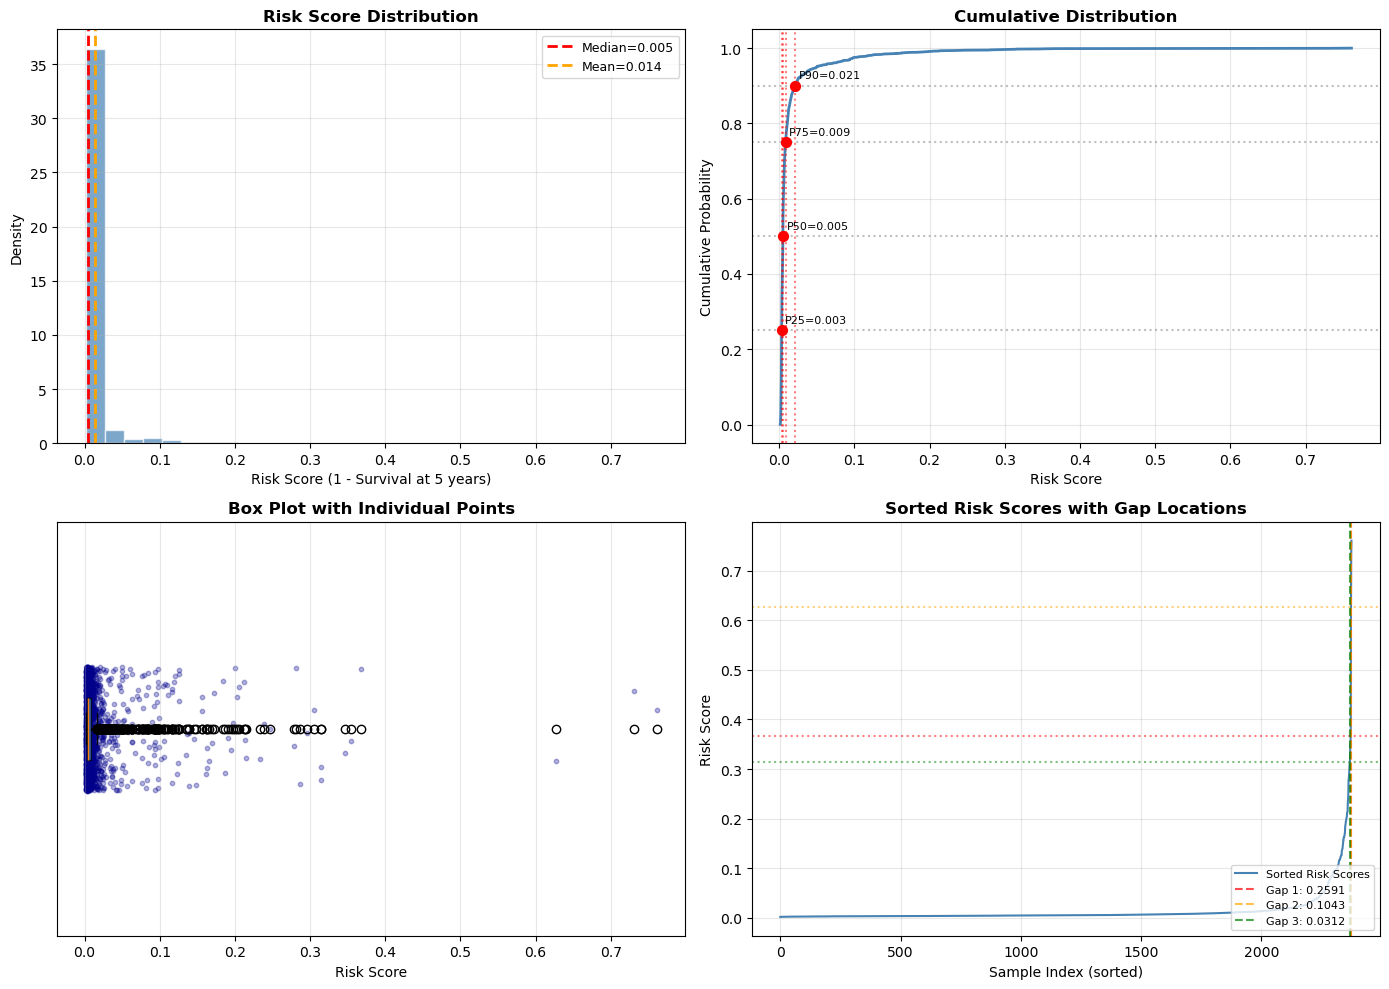


SUGGESTED BINNING STRATEGIES

1. Percentile-based (70/95):
   Low: 0 - 0.0070
   High: 0.0070 - 0.0502
   Very High: > 0.0502

2. Gap-based (natural breakpoints):
   Low: 0 - 0.4971
   Medium: 0.4971 - 0.6788
   High: > 0.6788


In [10]:
# ============================================
# GAP ANALYSIS FOR OPTIMAL BIN SPLITTING
# ============================================
# Use the risk scores (1 - survival at 5 years) to find natural breakpoints

# Get risk scores at 5-year time point (1825 days)
time_point_gap = 1825
time_idx_gap = time_points_eval.index(time_point_gap) if time_point_gap in time_points_eval else 1
risk_scores_gap = 1 - combined_preds_after[:, time_idx_gap]

print("="*70)
print("GAP ANALYSIS FOR RISK SCORE DISTRIBUTION")
print("="*70)

# Basic statistics
print(f"\nBasic Statistics:")
print(f"  Min:    {risk_scores_gap.min():.4f}")
print(f"  Max:    {risk_scores_gap.max():.4f}")
print(f"  Mean:   {risk_scores_gap.mean():.4f}")
print(f"  Median: {np.median(risk_scores_gap):.4f}")
print(f"  Std:    {risk_scores_gap.std():.4f}")

# Percentile analysis
percentiles_gap = [0, 5, 10, 20, 25, 30, 33.33, 40, 50, 60, 66.67, 70, 75, 80, 90, 95, 100]
print(f"\nPercentile Analysis:")
for p in percentiles_gap:
    val = np.percentile(risk_scores_gap, p)
    print(f"  {p:6.2f}%: {val:.4f}")

# Find natural gaps in the distribution
sorted_risks_gap = np.sort(risk_scores_gap)
gaps = np.diff(sorted_risks_gap)

# Find top 5 largest gaps
n_gaps = min(5, len(gaps))
large_gaps_idx = np.argsort(gaps)[-n_gaps:][::-1]  # Top 5 largest gaps

print(f"\nTop {n_gaps} Largest Gaps:")
for i, idx in enumerate(large_gaps_idx):
    gap_size = gaps[idx]
    position = (sorted_risks_gap[idx] + sorted_risks_gap[idx + 1]) / 2
    percentile_pos = (idx + 0.5) / len(sorted_risks_gap) * 100
    print(f"  Gap {i+1}: Size={gap_size:.4f}, Position={position:.4f}, Percentile≈{percentile_pos:.1f}%")

# Visualization - 4 panel plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Histogram with KDE
ax1 = axes[0, 0]
ax1.hist(risk_scores_gap, bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='white')
ax1.set_xlabel('Risk Score (1 - Survival at 5 years)', fontsize=10)
ax1.set_ylabel('Density', fontsize=10)
ax1.set_title('Risk Score Distribution', fontsize=12, fontweight='bold')
ax1.axvline(np.median(risk_scores_gap), color='red', linestyle='--', linewidth=2, label=f'Median={np.median(risk_scores_gap):.3f}')
ax1.axvline(risk_scores_gap.mean(), color='orange', linestyle='--', linewidth=2, label=f'Mean={risk_scores_gap.mean():.3f}')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel 2: Cumulative distribution
ax2 = axes[0, 1]
sorted_data = np.sort(risk_scores_gap)
cumulative = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
ax2.plot(sorted_data, cumulative, color='steelblue', linewidth=2)
ax2.set_xlabel('Risk Score', fontsize=10)
ax2.set_ylabel('Cumulative Probability', fontsize=10)
ax2.set_title('Cumulative Distribution', fontsize=12, fontweight='bold')
# Add percentile markers
for p in [25, 50, 75, 90]:
    val = np.percentile(risk_scores_gap, p)
    ax2.axhline(p/100, color='gray', linestyle=':', alpha=0.5)
    ax2.axvline(val, color='red', linestyle=':', alpha=0.5)
    ax2.scatter([val], [p/100], color='red', s=50, zorder=5)
    ax2.text(val + 0.005, p/100 + 0.02, f'P{p}={val:.3f}', fontsize=8)
ax2.grid(True, alpha=0.3)

# Panel 3: Box plot with individual points
ax3 = axes[1, 0]
bp = ax3.boxplot(risk_scores_gap, vert=False, patch_artist=True)
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][0].set_alpha(0.7)
ax3.scatter(risk_scores_gap, np.ones(len(risk_scores_gap)) + (np.random.rand(len(risk_scores_gap)) - 0.5) * 0.3, 
            alpha=0.3, s=10, color='darkblue')
ax3.set_xlabel('Risk Score', fontsize=10)
ax3.set_title('Box Plot with Individual Points', fontsize=12, fontweight='bold')
ax3.set_yticks([])
ax3.grid(True, alpha=0.3, axis='x')

# Panel 4: Gap analysis visualization
ax4 = axes[1, 1]
ax4.plot(range(len(sorted_risks_gap)), sorted_risks_gap, color='steelblue', linewidth=1.5, label='Sorted Risk Scores')
# Highlight large gaps
for i, idx in enumerate(large_gaps_idx[:3]):  # Top 3 gaps
    ax4.axvline(idx, color=['red', 'orange', 'green'][i], linestyle='--', 
                alpha=0.7, label=f'Gap {i+1}: {gaps[idx]:.4f}')
    ax4.axhline(sorted_risks_gap[idx], color=['red', 'orange', 'green'][i], 
                linestyle=':', alpha=0.5)
ax4.set_xlabel('Sample Index (sorted)', fontsize=10)
ax4.set_ylabel('Risk Score', fontsize=10)
ax4.set_title('Sorted Risk Scores with Gap Locations', fontsize=12, fontweight='bold')
ax4.legend(fontsize=8, loc='lower right')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gbm_breslow_gap_analysis.png', dpi=300, bbox_inches='tight')
print("\n✓ Gap analysis plot saved to 'gbm_breslow_gap_analysis.png'")
plt.show()

# Suggest optimal binning based on gaps
print(f"\n" + "="*70)
print("SUGGESTED BINNING STRATEGIES")
print("="*70)

# Strategy 1: Percentile-based (current)
print(f"\n1. Percentile-based (70/95):")
print(f"   Low: 0 - {np.percentile(risk_scores_gap, 70):.4f}")
print(f"   High: {np.percentile(risk_scores_gap, 70):.4f} - {np.percentile(risk_scores_gap, 95):.4f}")
print(f"   Very High: > {np.percentile(risk_scores_gap, 95):.4f}")

# Strategy 2: Gap-based (using top 2 gaps)
gap1_pos = (sorted_risks_gap[large_gaps_idx[0]] + sorted_risks_gap[large_gaps_idx[0] + 1]) / 2
if len(large_gaps_idx) > 1:
    gap2_pos = (sorted_risks_gap[large_gaps_idx[1]] + sorted_risks_gap[large_gaps_idx[1] + 1]) / 2
    cutoffs = sorted([gap1_pos, gap2_pos])
    print(f"\n2. Gap-based (natural breakpoints):")
    print(f"   Low: 0 - {cutoffs[0]:.4f}")
    print(f"   Medium: {cutoffs[0]:.4f} - {cutoffs[1]:.4f}")
    print(f"   High: > {cutoffs[1]:.4f}")

✓ Calibration plot saved!

Risk Categories:
  Low Risk: Bottom 33%
  High Risk: 33-66%
  Very High Risk: Top 34%


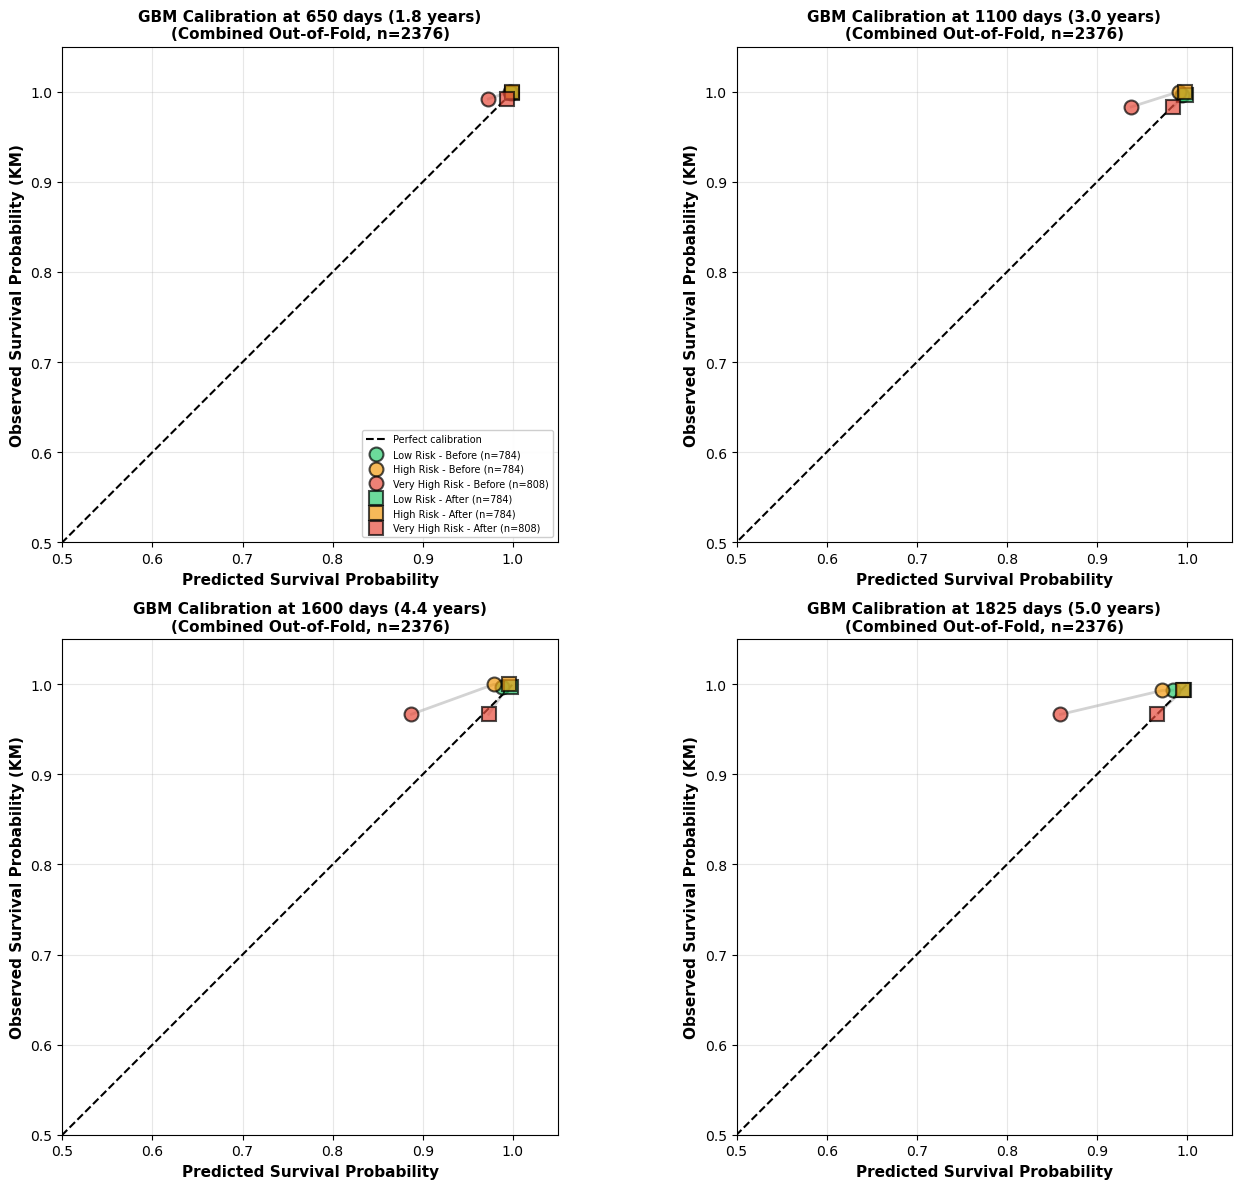


✓ Calibration data saved to 'gbm_breslow_calibration_data.csv'
  Columns: ['time_point', 'risk_bin', 'risk_category', 'mean_pred_before', 'mean_pred_after', 'mean_observed', 'mean_risk_pred_before', 'mean_risk_pred_after', 'mean_risk_observed', 'bin_size']


In [11]:
# CALIBRATION PLOT using combined out-of-fold predictions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

# Risk bin definitions
percentile_thresholds = [33, 66]

for idx, time_point in enumerate(time_points_eval):
    ax = axes[idx]
    
    pred_surv_before = combined_preds_before[:, idx]
    pred_surv_after = combined_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins based on percentiles
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    # Assign risk categories (3 bins)
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1   # High risk
    risk_labels[risk_scores > thresh_high] = 2  # Very high risk

    risk_names = ['Low Risk', 'High Risk', 'Very High Risk']
    colors_bins = ['#2ecc71', '#f39c12', '#e74c3c']  # Green, Orange, Red
    
    mean_pred_before = []
    mean_pred_after = []
    mean_observed = []
    bin_sizes = []
    
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        bin_sizes.append(mask.sum())
        
        if mask.sum() == 0:
            continue
        
        mean_pred_before.append(pred_surv_before[mask].mean())
        mean_pred_after.append(pred_surv_after[mask].mean())
        
        km_time, km_prob = kaplan_meier_estimator(
            combined_y['event'][mask],
            combined_y['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        mean_observed.append(obs_surv)
    
    # Plot
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)
    
    # Connecting lines
    ax.plot(mean_pred_before, mean_observed, '-', color='lightgray', linewidth=2, zorder=1)
    ax.plot(mean_pred_after, mean_observed, '-', color='lightgray', linewidth=2, zorder=1)
    
    # Markers - BEFORE calibration
    for i in range(len(mean_pred_before)):
        label_before = f'{risk_names[i]} - Before (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_before[i]], [mean_observed[i]], 'o',
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_before, zorder=3)
    
    # Markers - AFTER calibration
    for i in range(len(mean_pred_after)):
        label_after = f'{risk_names[i]} - After (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_after[i]], [mean_observed[i]], 's',
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_after, zorder=3)
    
    ax.set_xlabel('Predicted Survival Probability', fontsize=11, fontweight='bold')
    ax.set_ylabel('Observed Survival Probability (KM)', fontsize=11, fontweight='bold')
    ax.set_title(f'GBM Calibration at {time_point} days ({time_point/365:.1f} years)\n(Combined Out-of-Fold, n={len(combined_y)})', 
                 fontsize=11, fontweight='bold')
    if idx == 0:
        ax.legend(loc='lower right', fontsize=7, framealpha=0.95, ncol=1)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.5, 1.05)
    ax.set_ylim(0.5, 1.05)
    ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('gbm_breslow_calibration_cv.png', dpi=300, bbox_inches='tight')
plt.savefig('gbm_breslow_calibration_cv.pdf', dpi=300, bbox_inches='tight')
print("✓ Calibration plot saved!")
print(f"\nRisk Categories:")
print(f"  Low Risk: Bottom {percentile_thresholds[0]}%")
print(f"  High Risk: {percentile_thresholds[0]}-{percentile_thresholds[1]}%")
print(f"  Very High Risk: Top {100-percentile_thresholds[1]}%")
plt.show()

# ============================================
# Save calibration data to CSV
# ============================================
calibration_data = []

for idx, time_point in enumerate(time_points_eval):
    pred_surv_before = combined_preds_before[:, idx]
    pred_surv_after = combined_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins based on percentiles
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    # Assign risk categories (3 bins)
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1
    risk_labels[risk_scores > thresh_high] = 2
    
    risk_names = ['Low Risk', 'High Risk', 'Very High Risk']
    
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        bin_size = mask.sum()
        
        if bin_size == 0:
            continue
        
        mean_pred_before = pred_surv_before[mask].mean()
        mean_pred_after = pred_surv_after[mask].mean()
        
        km_time, km_prob = kaplan_meier_estimator(
            combined_y['event'][mask],
            combined_y['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        calibration_data.append({
            'time_point': time_point,
            'risk_bin': bin_idx,
            'risk_category': risk_names[bin_idx],
            'mean_pred_before': mean_pred_before,
            'mean_pred_after': mean_pred_after,
            'mean_observed': obs_surv,
            'mean_risk_pred_before': 1 - mean_pred_before,
            'mean_risk_pred_after': 1 - mean_pred_after,
            'mean_risk_observed': 1 - obs_surv,
            'bin_size': bin_size
        })

# Save to CSV
calibration_df = pd.DataFrame(calibration_data)
calibration_df.to_csv('gbm_breslow_calibration_data.csv', index=False)
print(f"\n✓ Calibration data saved to 'gbm_breslow_calibration_data.csv'")
print(f"  Columns: {list(calibration_df.columns)}")

Timepoint  | Slope      | Intercept  | AUC       
--------------------------------------------------
650        | 0.822      | -0.532     | 0.776     
1100       | 0.913      | 0.010      | 0.803     
1600       | 0.806      | -0.144     | 0.837     
1825       | 0.685      | -0.517     | 0.767     


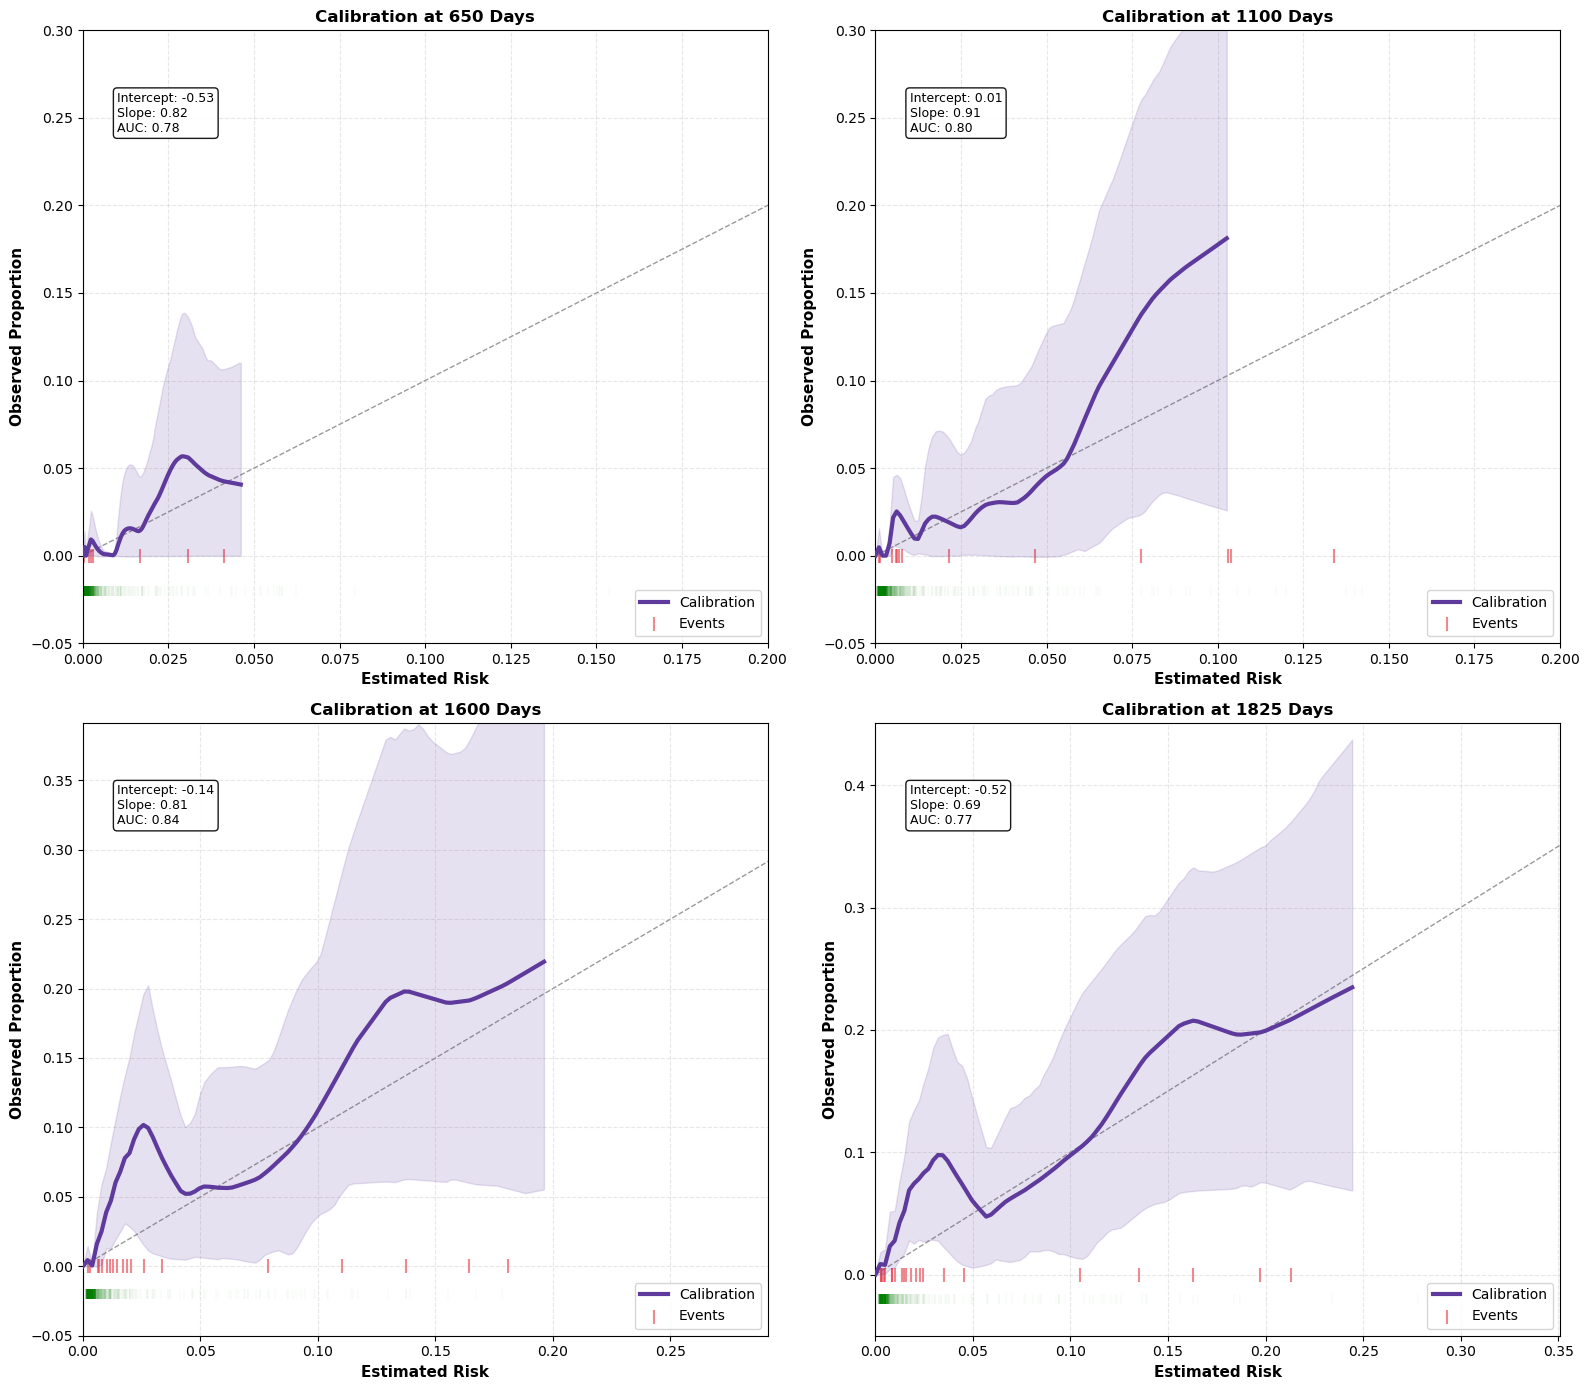

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.utils import resample
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.special import expit, logit

# ============================================
# HELPER: Bootstrap with Safety Checks
# ============================================
def bootstrap_calibration_safe(y_true, y_pred, n_boot=100, smooth_frac=0.4):
    """
    Robust bootstrap that handles sparse tails.
    """
    # Define grid only up to the max prediction to avoid "crashing" the curve
    max_val = np.percentile(y_pred, 99) * 1.2
    if max_val > 1.0: max_val = 1.0
    x_grid = np.linspace(0, max_val, 100)
    
    boot_predictions = []
    
    for i in range(n_boot):
        # Resample
        y_t_boot, y_p_boot = resample(y_true, y_pred, random_state=i)
        
        # Fit LOESS
        # We catch warnings to keep the output clean
        try:
            smoothed = lowess(y_t_boot, y_p_boot, frac=smooth_frac, it=0, return_sorted=True)
            
            # Interpolate safely
            # We assume the curve is flat (linear) past the last data point
            boot_line = np.interp(x_grid, smoothed[:, 0], smoothed[:, 1], left=0, right=smoothed[-1, 1])
            boot_predictions.append(boot_line)
        except:
            continue
            
    if len(boot_predictions) == 0:
        return x_grid, x_grid, x_grid, x_grid # Fail gracefully
        
    boot_predictions = np.array(boot_predictions)
    
    # 95% CI
    ci_lower = np.percentile(boot_predictions, 2.5, axis=0)
    ci_upper = np.percentile(boot_predictions, 97.5, axis=0)
    mean_curve = np.mean(boot_predictions, axis=0)
    
    return x_grid, mean_curve, ci_lower, ci_upper

# ============================================
# MAIN PLOTTING LOOP
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.ravel()

print(f"{'Timepoint':<10} | {'Slope':<10} | {'Intercept':<10} | {'AUC':<10}")
print("-" * 50)

for idx, time_point in enumerate(time_points_eval):
    if idx >= len(axes): break
    ax = axes[idx]
    
    # 1. Prepare Data
    # -------------------------------------------------------
    valid_mask = ~((combined_y['event'] == 0) & (combined_y['time'] < time_point))
    
    y_true = ((combined_y['time'][valid_mask] <= time_point) & (combined_y['event'][valid_mask] == 1)).astype(int)
    y_pred = 1 - combined_preds_after[valid_mask, idx]
    
    # Safety: Clip 0 and 1 to prevent log(0) errors (The cause of "Metrics Error")
    y_pred = np.clip(y_pred, 1e-6, 1 - 1e-6)

    # 2. Calculate Metrics (Robust Method)
    # -------------------------------------------------------
    try:
        # Calculate Log-Odds (Logit)
        log_odds = logit(y_pred).reshape(-1, 1)
        
        # Fit Logistic Regression (Sklearn is more stable than Statsmodels here)
        clf = LogisticRegression(C=1e9, solver='lbfgs') # C=large means no regularization (pure fit)
        clf.fit(log_odds, y_true)
        
        slope = clf.coef_[0][0]
        intercept = clf.intercept_[0]
        
        auc = roc_auc_score(y_true, y_pred)
        
        # Text for the plot
        stats_text = (f"Intercept: {intercept:.2f}\n"
                      f"Slope: {slope:.2f}\n"
                      f"AUC: {auc:.2f}")
        
        print(f"{time_point:<10} | {slope:<10.3f} | {intercept:<10.3f} | {auc:<10.3f}")
        
    except Exception as e:
        print(f"Metrics failed at {time_point}: {e}")
        stats_text = "Metrics Error\n(Data too sparse)"

    # 3. Generate Curve
    # -------------------------------------------------------
    # We increase 'frac' slightly (0.5) to make the curve smoother and less jittery
    x_grid, mean_curve, ci_lower, ci_upper = bootstrap_calibration_safe(y_true, y_pred, n_boot=100, smooth_frac=0.5)

    # 4. Plotting
    # -------------------------------------------------------
    
    # A. Perfect Line
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.4, zorder=1)
    
    # B. Smooth Curve & CI
    ax.plot(x_grid, mean_curve, color='#5D3A9B', linewidth=3, zorder=3, label='Calibration')
    ax.fill_between(x_grid, ci_lower, ci_upper, color='#5D3A9B', alpha=0.15, zorder=2)
    
    # C. Rug Plot (Survivors vs Events)
    # We separate them to see where the risks actually land
    
    # Events (Top red ticks)
    events_risk = y_pred[y_true == 1]
    ax.scatter(events_risk, np.ones_like(events_risk) * 0.0, 
               marker='|', color='#E63946', alpha=0.6, s=100, label='Events')
               
    # Survivors (Bottom green ticks, very transparent)
    surv_risk = y_pred[y_true == 0]
    ax.scatter(surv_risk, np.zeros_like(surv_risk) - 0.02, 
               marker='|', color='green', alpha=0.02, s=50)

    # 5. Formatting
    # -------------------------------------------------------
    # AUTO-ZOOM: Determine the max x-limit based on data
    # If your max risk is 0.25, show up to 0.3. Don't show empty space up to 1.0
    max_disp = np.percentile(y_pred, 99.5)
    max_disp = min(max_disp * 1.2, 1.0) # Add 20% buffer, cap at 1.0
    if max_disp < 0.2: max_disp = 0.2 # Minimum width
    
    ax.set_xlim(0, max_disp)
    ax.set_ylim(-0.05, max_disp + 0.1) # Scale Y similarly to X for aspect ratio
    
    ax.set_xlabel('Estimated Risk', fontsize=11, fontweight='bold')
    ax.set_ylabel('Observed Proportion', fontsize=11, fontweight='bold')
    
    # Add stats box
    ax.text(0.05, 0.9, stats_text, transform=ax.transAxes, fontsize=9, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

    ax.set_title(f'Calibration at {time_point} Days', fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('final_calibration_zoomed.png', dpi=300)
plt.show()

GBM MODEL FEATURE EXTRACTION (AVERAGED ACROSS 4 FOLDS)

Feature importances averaged from 4 folds

Top 15 Features by Mean Importance:
---------------------------------------------------------------------------
Feature                                   Mean        Std   % of Total
---------------------------------------------------------------------------
Oestrogen receptor status at CB_0.0     0.1683     0.0866       16.83%
Age                                     0.0858     0.0213        8.58%
Radiotherapy (RT) performed             0.0745     0.0502        7.45%
Adjuvant therapy with bio drugs         0.0729     0.0424        7.29%
Endocrine therapy performed             0.0699     0.0504        6.99%
Oestrogen receptor status at CB_1.0     0.0619     0.0413        6.19%
N (Regional nodes affected)             0.0613     0.0251        6.13%
Istotype at CB_4.0                      0.0598     0.0747        5.98%
Total administered dose                 0.0391     0.0370        3.91%
Ki6

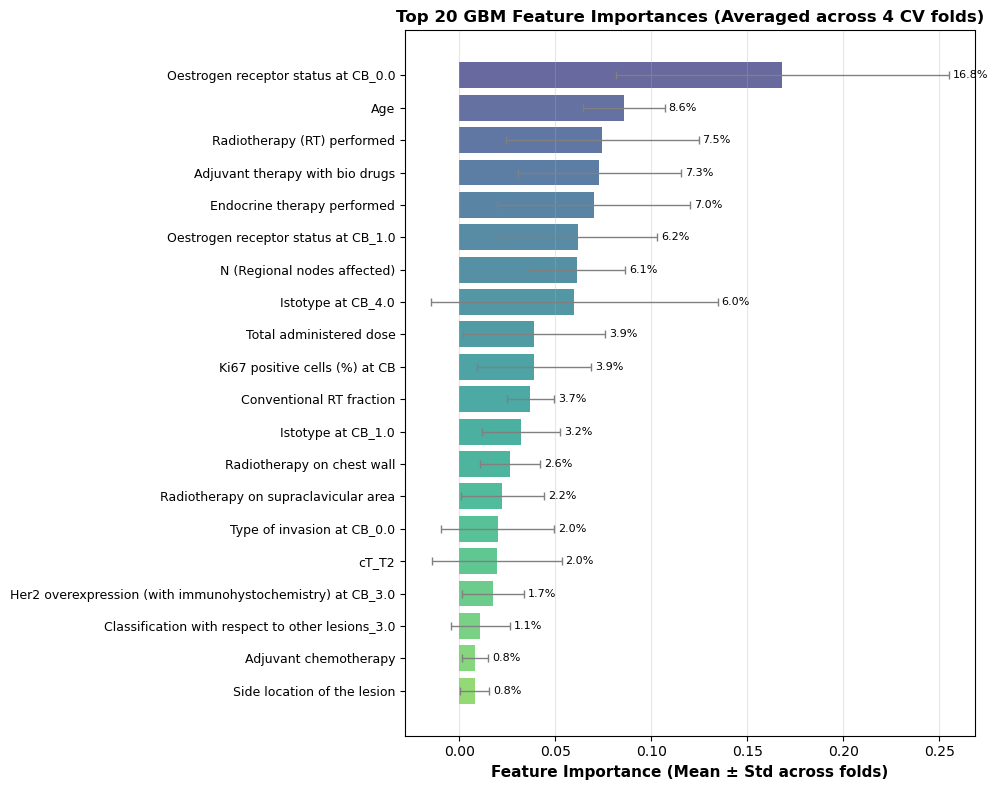

In [13]:
# ============================================
# FEATURE EXTRACTION - GBM FEATURE IMPORTANCE (AVERAGED ACROSS FOLDS)
# ============================================
# Display the most important features based on feature importance averaged across all CV folds

print("="*70)
print("GBM MODEL FEATURE EXTRACTION (AVERAGED ACROSS 4 FOLDS)")
print("="*70)

# Average feature importances across all folds
feature_importances_array = np.array(all_fold_feature_importances)
mean_feature_importance = np.mean(feature_importances_array, axis=0)
std_feature_importance = np.std(feature_importances_array, axis=0)

print(f"\nFeature importances averaged from {len(all_fold_feature_importances)} folds")

# Create feature importance DataFrame with mean and std
importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'Importance_Mean': mean_feature_importance,
    'Importance_Std': std_feature_importance
})

# Sort by mean importance value (descending)
importance_df = importance_df.sort_values('Importance_Mean', ascending=False)

# Normalize importance (percentage)
importance_df['Importance_Pct'] = importance_df['Importance_Mean'] / importance_df['Importance_Mean'].sum() * 100

# Display top features
print(f"\nTop 15 Features by Mean Importance:")
print("-" * 75)
print(f"{'Feature':<35} {'Mean':>10} {'Std':>10} {'% of Total':>12}")
print("-" * 75)
for i, row in importance_df.head(15).iterrows():
    print(f"{row['Feature']:<35} {row['Importance_Mean']:>10.4f} {row['Importance_Std']:>10.4f} {row['Importance_Pct']:>11.2f}%")

# Cumulative importance
importance_df['Cumulative_Pct'] = importance_df['Importance_Pct'].cumsum()
print(f"\nCumulative Importance:")
for n in [5, 10, 15, 20]:
    if n <= len(importance_df):
        cum_pct = importance_df.iloc[:n]['Importance_Pct'].sum()
        print(f"  Top {n:2d} features: {cum_pct:.1f}%")

# Features with zero importance in all folds
zero_importance = importance_df[importance_df['Importance_Mean'] == 0]
if len(zero_importance) > 0:
    print(f"\nFeatures with zero importance: {len(zero_importance)}")
    if len(zero_importance) <= 10:
        for i, row in zero_importance.iterrows():
            print(f"  - {row['Feature']}")

# Save feature importance to CSV
importance_df.to_csv('../../results/features/gbm_feature_importance.csv', index=False)
print(f"\n✓ Feature importance saved to '../../results/features/gbm_breslow_feature_importance.csv'")

# Visualization - Feature importance plot with error bars
fig, ax = plt.subplots(figsize=(10, 8))
top_n = min(20, len(importance_df))
top_features = importance_df.head(top_n)

colors = plt.cm.viridis(np.linspace(0.2, 0.8, top_n))
bars = ax.barh(range(top_n), top_features['Importance_Mean'], 
               xerr=top_features['Importance_Std'], color=colors, alpha=0.8,
               capsize=3, error_kw={'linewidth': 1, 'ecolor': 'gray'})

ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features['Feature'], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance (Mean ± Std across folds)', fontsize=11, fontweight='bold')
ax.set_title(f'Top {top_n} GBM Feature Importances (Averaged across 4 CV folds)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

# Add percentage labels
for i, (bar, pct) in enumerate(zip(bars, top_features['Importance_Pct'])):
    ax.text(bar.get_width() + top_features['Importance_Std'].iloc[i] + 0.002, 
            bar.get_y() + bar.get_height()/2, 
            f'{pct:.1f}%', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('gbm_breslow_feature_importance.png', dpi=300, bbox_inches='tight')
print("✓ Feature importance plot saved to 'gbm_breslow_feature_importance.png'")
plt.show()